# 07 · Итоговое сравнение и пример рекомендаций

Собираю результаты моделей в одну таблицу. Параметры выбирались на неделе 9–15 августа, а здесь сравнивается следующая неделя — 16–22 августа. У всех моделей одинаковые пользователи, цели и каталог.

К исходным семи подходам добавляю свежую популярность. Её окно также выбрано по предыдущей неделе. Подробности этого сравнения, вклад признаков CatBoost и оценка на трёх неделях разобраны в [ноутбуке 08](08_robustness.ipynb).

Все модели обучены на полной доступной истории. В Test оцениваются 106 819 пользователей, у которых есть хотя бы один новый положительный объект.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA_DIR = Path(os.environ.get("KION_DATA_DIR", ROOT / "data"))
REPORTS = ROOT / "reports" / "full"
K = 10
blas_limit = threadpool_limits(limits=1, user_api="blas")
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## Сравнение

,Users,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage
model,,,,,,
Popularity,106819,0.12149,0.23660,0.15985,0.31267,0.00271
ItemKNN,106819,0.12571,0.24867,0.16734,0.33652,0.34622
ALS,106819,0.10118,0.21584,0.13857,0.29495,0.06211
BPR,106819,0.08512,0.17041,0.11266,0.22401,0.50852
Content,106819,0.06709,0.13427,0.08800,0.16800,0.51583
Hybrid,106819,0.10556,0.23037,0.14600,0.31543,0.23850
CatBoost,106819,0.14556,0.28325,0.19203,0.38143,0.14375
RecentPopularity,106819,0.13195,0.26895,0.17616,0.35514,0.00256


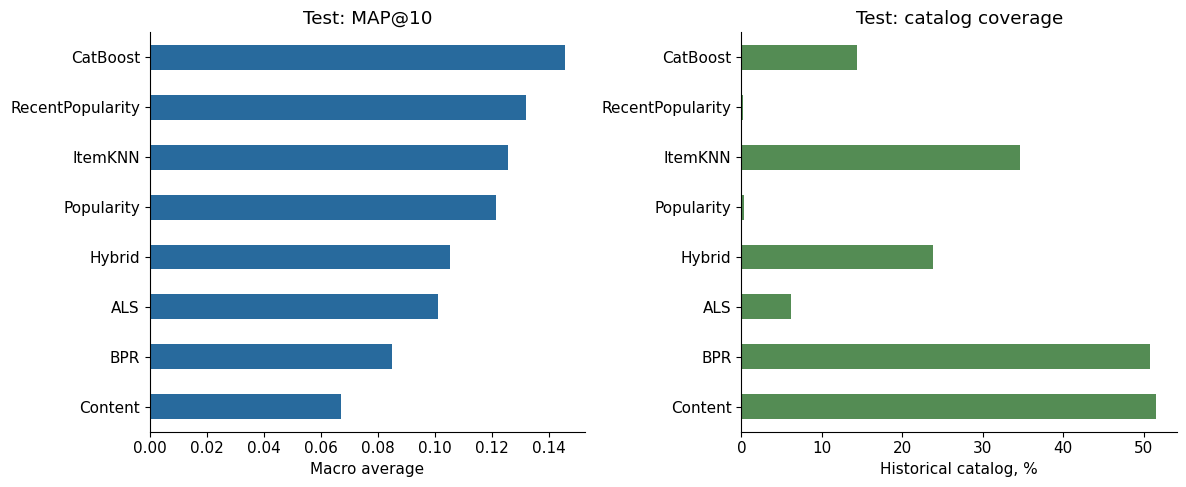

In [2]:
metric_columns = ["MAP@10", "Recall@10", "NDCG@10", "HitRate@10", "Coverage"]
metrics = pd.read_csv(REPORTS / "metrics.csv")
study = pd.read_csv(ROOT / "reports" / "study" / "metrics.csv")
recent = study.loc[
    study.test_start.eq("2021-08-16") & study.model.str.startswith("RecentPopularity")
].copy()
recent["model"] = "RecentPopularity"
test_results = pd.concat(
    [
        metrics.query("split == 'test'")[["model", "Users"] + metric_columns],
        recent[["model", "Users"] + metric_columns],
    ]
).set_index("model")
display(test_results.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
test_results.sort_values("MAP@10")["MAP@10"].plot.barh(ax=axes[0], color="#286a9d")
test_results.sort_values("MAP@10")["Coverage"].mul(100).plot.barh(
    ax=axes[1], color="#548c54"
)
axes[0].set(title="Test: MAP@10", xlabel="Macro average", ylabel="")
axes[1].set(title="Test: catalog coverage", xlabel="Historical catalog, %", ylabel="")
plt.tight_layout()
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports" / "figures" / "model_comparison.png", dpi=160)
plt.show()

## Короткая история и холодный старт

model,ALS,BPR,CatBoost,Content,Hybrid,ItemKNN,Popularity
segment,,,,,,,
cold,0.1863,0.1863,0.2032,0.1863,0.1863,0.1863,0.1863
1,0.0820,0.0729,0.1738,0.0053,0.0928,0.1321,0.1508
2-5,0.0649,0.0327,0.1303,0.0050,0.0714,0.1092,0.1039
6-20,0.0448,0.0181,0.0916,0.0033,0.0500,0.0761,0.0595
21+,0.0282,0.0104,0.0588,0.0017,0.0343,0.0469,0.0317


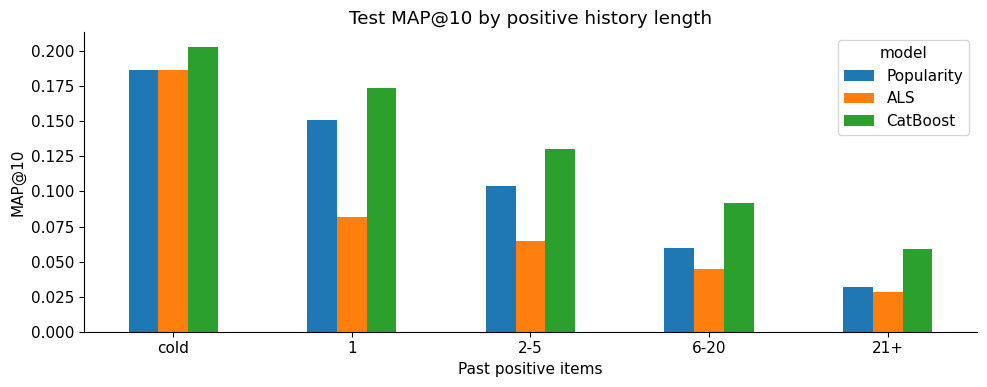

In [3]:
segments = pd.read_csv(REPORTS / "segments.csv")
segment_order = ["cold", "1", "2-5", "6-20", "21+"]
segment_scores = (
    segments.query("split == 'test'")
    .pivot(index="segment", columns="model", values="MAP@10")
    .reindex(segment_order)
)
display(segment_scores.round(4))
fig, ax = plt.subplots(figsize=(10, 4))
segment_scores[["Popularity", "ALS", "CatBoost"]].plot.bar(ax=ax, rot=0)
ax.set(
    title="Test MAP@10 by positive history length",
    xlabel="Past positive items",
    ylabel="MAP@10",
)
plt.tight_layout()
plt.show()

## Пример персональных рекомендаций

Для примера взял первого по ID пользователя с пятью и более положительными просмотрами — пользователя 3. Ниже его недавняя история до 16 августа и десять рекомендаций CatBoost.

In [4]:
run = json.loads((REPORTS / "run.json").read_text())
print("User:", run["example_user"])
history = pd.read_csv(REPORTS / "example_history.csv")
display(history[["title", "last_watch_dt", "watched_pct"]].tail(10))
recommendations = pd.read_csv(REPORTS / "example_recommendations.csv")
display(
    recommendations.assign(rank=np.arange(1, len(recommendations) + 1))[
        ["rank", "title", "genres"]
    ]
)

User: 3


,title,last_watch_dt,watched_pct
5,Выстрел в пустоту,2021-07-25,100.0
6,Няня,2021-07-25,26.0
7,Вирус страха,2021-07-26,97.0
8,Дружить по-русски,2021-07-27,100.0
9,Игры дьявола,2021-07-30,48.0
10,Не входи,2021-07-30,20.0
11,С днём смерти,2021-08-04,100.0
12,Семейка Бигфутов,2021-08-11,97.0
13,Страна чудес Вилли,2021-08-12,100.0
14,Маша,2021-08-13,100.0


,rank,title,genres
0,1,Клиника счастья,"драмы, мелодрамы"
1,2,Девятаев,"драмы, военные, приключения"
2,3,Поступь хаоса,"боевики, фантастика, фэнтези, приключения"
3,4,Немцы,драмы
4,5,Волк с Уолл-стрит,"драмы, биография, криминал, комедии"
5,6,Экстрасенс 2: Лабиринты разума,"драмы, триллеры, криминал, детективы"
6,7,Убийство онлайн,триллеры
7,8,Приворот. Чёрное венчание,"ужасы, триллеры, мелодрамы"
8,9,2067: Петля времени,"драмы, фантастика"
9,10,Стендап под прикрытием,комедии


## Что получилось

Полный CatBoost получил MAP@10 **0.1456**. Его преимущество относительно исходного Popularity составляет **19.8%**, а относительно свежей популярности — **10.3%**. Свежий baseline заметно сокращает разницу, но второй этап всё ещё даёт улучшение.

ItemKNN немного улучшил исходный baseline и расширил покрытие. ALS, BPR, Content и смешивание рангов в проверенных конфигурациях не дали лучшего самостоятельного результата.

CatBoost оказался выше свежей популярности на всех трёх неделях: относительный прирост MAP@10 составил от 9,0% до 10,3%. Абсолютное качество меняется от недели к неделе, но преимущество ранкера в этом сравнении сохранилось.

В [ноутбуке 08](08_robustness.ipynb) отдельно разобран вклад признаков. В данных видны просмотры, но нет показов рекомендаций, поэтому здесь оценивается предсказание будущих просмотров. Влияние системы на поведение пользователей по этим результатам определить нельзя.